# Reproduction of the Matters Arising on Chanda et al. (2024)

We reproduce in this notebook every number, figure and table of our Matters Arising on the concept labels released by Chanda et al. (2024). We follow the order of the manuscript and tag each check with the paragraph, figure or table that it verifies.

We end every check with an assertion, so the notebook stops when a value differs from the manuscript. We collect all checks in one table in the last section.

We use the files that Chanda et al. released on Figshare. The notebook reads them from the data folder of this package, or from the path in the environment variable CHANDA_DATA, and unzips Datasets.zip when needed.

In [1]:
import os
import itertools
import zipfile
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = os.environ.get("CHANDA_DATA", os.path.join("..", "data"))
OUT = "source_data"
os.makedirs(OUT, exist_ok=True)

# Unzip the nested archive with the individual records when the folder is missing
if not os.path.isdir(os.path.join(ROOT, "Datasets")):
    with zipfile.ZipFile(os.path.join(ROOT, "Datasets.zip")) as z:
        z.extractall(ROOT)

gt = pd.read_csv(os.path.join(ROOT, "metadata_gt.csv"))                              # merged labels and split
ann = pd.read_csv(os.path.join(ROOT, "Datasets", "metadata", "metadata_ground_truth.csv"))  # one row per annotator and image
study = pd.read_csv(os.path.join(ROOT, "Datasets", "metadata", "metadata_study.csv"))      # phase 1 records of the reader study

# Concept codes of the ontology, grouped by the pool of each class
M = ["TRBL", "ESA", "BDG", "GP", "PV", "PRL", "WLSA", "PLR", "PES", "PIF"]   # melanoma concepts
N = ["OPC", "SPC", "MVP", "PRLC", "PLF", "PDES", "APC", "MS"]               # nevus concepts
POOL = M + N
ALL = POOL + ["None"]
Y = gt["benign_malignant"].to_numpy()                                       # 1 for melanoma, 0 for nevus

RESULTS = []


def check(sentence, what, value, expected, ok):
    # Store and print one check, then stop the notebook if it fails
    RESULTS.append(dict(sentence=sentence, check=what, value=value, manuscript=expected, passed=bool(ok)))
    print(f"{sentence} | {what} = {value} | manuscript {expected}")
    assert ok, f"{sentence} failed"


def kappa(x, y):
    # Cohen's kappa for two binary raters
    x, y = np.asarray(x, float), np.asarray(y, float)
    po = (x == y).mean()
    pe = x.mean() * y.mean() + (1 - x.mean()) * (1 - y.mean())
    return (po - pe) / (1 - pe)


print(len(gt), len(ann), len(study))

3611 6498 1560


## 1. Released data

We first verify the description of the annotated dataset in the opening paragraph and in the protocol paragraph. Chanda et al. asked 14 dermatologists to annotate images from HAM10000, and we count them in the released records.

In [2]:
n_json = sum(len(f) for _, _, f in os.walk(os.path.join(ROOT, "Datasets", "ground_truth_annotations")))
check("Opening", "images", len(gt), 3611, len(gt) == 3611)
check("Opening", "lesions", gt.lesion_id.nunique(), 1981, gt.lesion_id.nunique() == 1981)
check("Opening", "pool concepts", len(POOL), 18, len(POOL) == 18)
check("Opening", "annotating dermatologists", ann.annotator.nunique(), 14, ann.annotator.nunique() == 14)
check("Opening", "annotation files with regions of interest", n_json, 6498, n_json == 6498)
dx = ann.drop_duplicates("image_id").dx_type.unique().tolist()
check("Protocol", "diagnosis types", dx, "histopathology only", dx == ["histo"])
check("Protocol", "melanoma and nevus concepts", (len(M), len(N)), "(10, 8)", (len(M), len(N)) == (10, 8))
check("Protocol", "annotation records", len(ann), 6498, len(ann) == 6498)

Opening | images = 3611 | manuscript 3611
Opening | lesions = 1981 | manuscript 1981
Opening | pool concepts = 18 | manuscript 18
Opening | annotating dermatologists = 14 | manuscript 14
Opening | annotation files with regions of interest = 6498 | manuscript 6498
Protocol | diagnosis types = ['histo'] | manuscript histopathology only
Protocol | melanoma and nevus concepts = (10, 8) | manuscript (10, 8)
Protocol | annotation records = 6498 | manuscript 6498


## 2. A diagnosis-conditional protocol

We now test whether any record combines concepts from both pools and whether the concept labels determine the diagnosis. We then reproduce Table 1, which applies simple diagnostic rules to the concept labels alone.

In [3]:
mix = ((ann[M].max(axis=1) == 1) & (ann[N].max(axis=1) == 1)).sum()
check("Protocol", "records with concepts from both pools", int(mix), 0, mix == 0)

own_pool = np.where(Y == 1, gt[M].max(axis=1), gt[N].max(axis=1))
check("Protocol", "images without a concept of their own pool", int((own_pool == 0).sum()), 0, (own_pool == 0).sum() == 0)

y_from_x = gt[M].max(axis=1).to_numpy()
check("Protocol", "images where the diagnosis equals the maximum of the melanoma concept labels", int((y_from_x == Y).sum()), 3611, (y_from_x == Y).all())

def bacc(pred, y):
    # Balanced accuracy of a binary melanoma prediction
    pred, y = np.asarray(pred), np.asarray(y)
    return 0.5 * ((pred[y == 1] == 1).mean() + (pred[y == 0] == 0).mean())


rules = {
    "Melanoma simulator absent": (1, (gt.MS == 0).astype(int)),
    "Grey patterns present": (1, gt.GP),
    "Thick reticular lines present": (1, gt.TRBL),
    "Two or more melanoma concepts (Chanda et al.)": (10, (gt[M].sum(axis=1) >= 2).astype(int)),
    "Any melanoma concept present": (10, gt[M].max(axis=1)),
}
test = (gt.split == "test").to_numpy()
table1 = pd.DataFrame({name: {"Labels read": k,
                              "Test images": round(bacc(p[test], Y[test]), 3),
                              "All images": round(bacc(p, Y), 3)} for name, (k, p) in rules.items()}).T
reported = pd.DataFrame({"Labels read": ["", "", ""], "Test images": [0.81, 0.66, 0.73], "All images": ["", "", ""]},
                        index=["XAI reading the images", "Clinicians without AI (phase 1)", "Clinicians with XAI (phase 3)"])
table1["Concept labels read"] = table1["Labels read"].astype(int).astype(str)
table1 = table1.drop(columns="Labels read")
table1["Source"] = "Computed from the concept labels"
reported = reported.rename(columns={"Labels read": "Concept labels read"})
reported["Source"] = "Reported by Chanda et al."
table1_full = pd.concat([table1, reported])[["Concept labels read", "Test images", "All images", "Source"]]
table1_full.index.name = "Diagnostic rule"
table1_full.to_csv(os.path.join(OUT, "table1_source_data.csv"))
display(table1_full)
check("Table 1", "test images", int(test.sum()), 200, test.sum() == 200)
check("Table 1", "test balanced accuracy of the five rules", table1["Test images"].tolist(), "[0.98, 0.98, 0.955, 1.0, 1.0]",
      table1["Test images"].tolist() == [0.98, 0.98, 0.955, 1.0, 1.0])
check("Table 1", "balanced accuracy of the five rules on all images", table1["All images"].tolist(), "[0.989, 0.97, 0.952, 0.997, 1.0]",
      table1["All images"].tolist() == [0.989, 0.97, 0.952, 0.997, 1.0])
ms_rule = (gt.MS == 0).astype(int).to_numpy()
ms_ok = int((ms_rule[test] == Y[test]).sum())
check("Summary and Protocol", "test images recovered by the absence of melanoma simulator", ms_ok, "196 of 200", ms_ok == 196)
check("Protocol", "melanomas that carry melanoma simulator", int(gt.loc[Y == 1, "MS"].sum()), 0, gt.loc[Y == 1, "MS"].sum() == 0)
correct = int(((gt[M].sum(axis=1) >= 2).astype(int).to_numpy() == Y).sum())
print(f"images recovered by the rule of Chanda et al. = {correct} of {len(gt)}")

Protocol | records with concepts from both pools = 0 | manuscript 0
Protocol | images without a concept of their own pool = 0 | manuscript 0
Protocol | images where the diagnosis equals the maximum of the melanoma concept labels = 3611 | manuscript 3611


,Concept labels read,Test images,All images,Source
Diagnostic rule,,,,
Melanoma simulator absent,1,0.980,0.989,Computed from the concept labels
Grey patterns present,1,0.980,0.97,Computed from the concept labels
Thick reticular lines present,1,0.955,0.952,Computed from the concept labels
Two or more melanoma concepts (Chanda et al.),10,1.000,0.997,Computed from the concept labels
Any melanoma concept present,10,1.000,1.0,Computed from the concept labels
XAI reading the images,,0.810,,Reported by Chanda et al.
Clinicians without AI (phase 1),,0.660,,Reported by Chanda et al.
Clinicians with XAI (phase 3),,0.730,,Reported by Chanda et al.


Table 1 | test images = 200 | manuscript 200
Table 1 | test balanced accuracy of the five rules = [0.98, 0.98, 0.955, 1.0, 1.0] | manuscript [0.98, 0.98, 0.955, 1.0, 1.0]
Table 1 | balanced accuracy of the five rules on all images = [0.989, 0.97, 0.952, 0.997, 1.0] | manuscript [0.989, 0.97, 0.952, 0.997, 1.0]
Summary and Protocol | test images recovered by the absence of melanoma simulator = 196 | manuscript 196 of 200
Protocol | melanomas that carry melanoma simulator = 0 | manuscript 0
images recovered by the rule of Chanda et al. = 3605 of 3611


The protocol paragraph states that a concept model can raise its concept accuracy by predicting the class. We compare two predictors that never look at an image. The first assigns each concept its majority concept label over all images, and the second assigns the majority concept label within the known class.

In [4]:
X = gt[POOL].to_numpy()
glob_major = (X.mean(axis=0) >= 0.5).astype(int)
acc_global = (X == glob_major).mean()
cls_major = {c: (X[Y == c].mean(axis=0) >= 0.5).astype(int) for c in (0, 1)}
pred_cls = np.vstack([cls_major[c] for c in Y])
acc_class = (X == pred_cls).mean()
print(f"concept accuracy without the class = {acc_global:.3f}")
print(f"concept accuracy from the class alone = {acc_class:.3f}")
check("Protocol", "class knowledge raises concept accuracy", float(round(acc_class - acc_global, 3)), "positive gain", acc_class > acc_global)

concept accuracy without the class = 0.855
concept accuracy from the class alone = 0.931
Protocol | class knowledge raises concept accuracy = 0.076 | manuscript positive gain


## 3. One annotator drives the most frequent concept labels

We reproduce the union rule, pair each record of annotators 2 to 14 with the annotator 1 record, and compute kappa on all pairs and within each class. These checks cover the agreement paragraph and the text on Figure 1.

In [5]:
union = ann.groupby("image_id")[ALL].max()
merged = gt.set_index("image_id")[ALL].loc[union.index]
check("Agreement", "merged concept label vectors reproduced by the union rule", int((union.values == merged.values).all(axis=1).sum()), 3611,
      (union.values == merged.values).all())

check("Agreement", "images annotated by annotator 1", int((ann.annotator == 1).sum()), 3611, (ann.annotator == 1).sum() == 3611)
check("Agreement", "further annotators", ann.annotator.nunique() - 1, 13, ann.annotator.nunique() - 1 == 13)

a1 = ann[ann.annotator == 1].set_index("image_id")[ALL]
pairs = ann[ann.annotator != 1].join(a1, on="image_id", rsuffix="_a1")
n_img = pairs.image_id.nunique()
check("Agreement", "paired records", len(pairs), 2887, len(pairs) == 2887)
check("Fig. 1", "images behind the paired records", n_img, 2616, n_img == 2616)

rows = []
for f in POOL:
    cls = 1 if f in M else 0
    sub = pairs[pairs.benign_malignant == cls]
    rows.append(dict(concept=f, pool="M" if cls else "N",
                     merged_prev=100 * gt.loc[Y == cls, f].mean(),
                     kappa_all=kappa(pairs[f], pairs[f + "_a1"]),
                     kappa_within=kappa(sub[f], sub[f + "_a1"]),
                     observed_within=(sub[f] == sub[f + "_a1"]).mean(),
                     prev_a1=100 * sub[f + "_a1"].mean(), prev_others=100 * sub[f].mean()))
agree = pd.DataFrame(rows).set_index("concept").sort_values("merged_prev", ascending=False)
agree.round(3)

Agreement | merged concept label vectors reproduced by the union rule = 3611 | manuscript 3611
Agreement | images annotated by annotator 1 = 3611 | manuscript 3611
Agreement | further annotators = 13 | manuscript 13
Agreement | paired records = 2887 | manuscript 2887
Fig. 1 | images behind the paired records = 2616 | manuscript 2616


,pool,merged_prev,kappa_all,kappa_within,observed_within,prev_a1,prev_others
concept,,,,,,,
MS,N,97.758,0.218,0.008,0.259,98.279,24.451
GP,M,94.070,0.352,0.029,0.345,94.592,30.449
TRBL,M,90.476,0.399,0.080,0.408,90.516,32.363
APC,N,82.786,0.287,0.098,0.404,82.730,25.519
BDG,M,81.941,0.390,0.127,0.458,78.785,29.118
ESA,M,53.908,0.333,0.165,0.605,22.712,45.092
WLSA,M,50.584,0.501,0.337,0.689,31.697,41.681
PV,M,47.889,0.342,0.226,0.637,45.424,15.641
SPC,N,31.906,0.126,0.041,0.652,13.531,31.276


In [6]:
top5 = agree.head(5)
print(top5.index.tolist())
kr = (float(round(top5.kappa_within.min(), 2)), float(round(top5.kappa_within.max(), 2)))
check("Figure 1 text", "within-class kappa range of the five most frequent concepts", kr, "(0.01, 0.13)", kr == (0.01, 0.13))
check("Figure 1", "grey patterns kappa, all pairs then within melanomas", (float(round(agree.loc["GP", "kappa_all"], 2)), float(round(agree.loc["GP", "kappa_within"], 2))),
      "(0.35, 0.03)", (float(round(agree.loc["GP", "kappa_all"], 2)), float(round(agree.loc["GP", "kappa_within"], 2))) == (0.35, 0.03))
check("Figure 1", "melanoma simulator kappa, all pairs then within nevi", (float(round(agree.loc["MS", "kappa_all"], 2)), float(round(agree.loc["MS", "kappa_within"], 2))),
      "(0.22, 0.01)", (float(round(agree.loc["MS", "kappa_all"], 2)), float(round(agree.loc["MS", "kappa_within"], 2))) == (0.22, 0.01))
gap = (top5.prev_a1 - top5.prev_others).abs()
check("Figure 1 text", "smallest prevalence gap among the five most frequent concepts (points)", float(round(gap.min(), 1)), "large gap", gap.min() > 45)
orange = (int(round(100 * top5.observed_within.min())), int(round(100 * top5.observed_within.max())))
check("Figure 1 text", "observed within-class agreement range of the five concepts (%)", orange, "(26, 46)", orange == (26, 46))
check("Figure 1 text", "annotator 1 selects each of the five concepts more often than the others", bool((top5.prev_a1 > top5.prev_others).all()),
      "True", (top5.prev_a1 > top5.prev_others).all())

['MS', 'GP', 'TRBL', 'APC', 'BDG']
Figure 1 text | within-class kappa range of the five most frequent concepts = (0.01, 0.13) | manuscript (0.01, 0.13)
Figure 1 | grey patterns kappa, all pairs then within melanomas = (0.35, 0.03) | manuscript (0.35, 0.03)
Figure 1 | melanoma simulator kappa, all pairs then within nevi = (0.22, 0.01) | manuscript (0.22, 0.01)
Figure 1 text | smallest prevalence gap among the five most frequent concepts (points) = 49.7 | manuscript large gap
Figure 1 text | observed within-class agreement range of the five concepts (%) = (26, 46) | manuscript (26, 46)
Figure 1 text | annotator 1 selects each of the five concepts more often than the others = True | manuscript True


In [7]:
others_pos = ann[ann.annotator != 1].groupby("image_id")[ALL].max().reindex(a1.index).fillna(0)
share = {}
for f in ["MS", "GP", "TRBL", "APC", "BDG"]:
    only_a1 = ((a1[f] == 1) & (others_pos[f] == 0)).sum()
    share[f] = round(100 * only_a1 / gt[f].sum())
check("Figure 1 text", "share of merged positives from annotator 1 alone (%)", {k: share[k] for k in ["MS", "GP", "TRBL"]}, "MS 83, GP 68, TRBL 64",
      [share[k] for k in ["MS", "GP", "TRBL"]] == [83, 68, 64])
check("Summary", "annotator 1 alone supplies most positives of all five frequent concepts", share, "above 50% each", min(share.values()) > 50)

Figure 1 text | share of merged positives from annotator 1 alone (%) = {'MS': 83, 'GP': 68, 'TRBL': 64} | manuscript MS 83, GP 68, TRBL 64
Summary | annotator 1 alone supplies most positives of all five frequent concepts = {'MS': 83, 'GP': 68, 'TRBL': 64, 'APC': 79, 'BDG': 66} | manuscript above 50% each


## 4. Figure 1

We redraw Figure 1 from the agreement table above and save it with its source data. The figure shows every concept with a prevalence above 5% for at least one rater group.

Figure 1 | concepts above 5% for at least one rater group = ['APC', 'BDG', 'ESA', 'GP', 'MS', 'OPC', 'PIF', 'PRL', 'PRLC', 'PV', 'SPC', 'TRBL', 'WLSA'] | manuscript 13 concepts


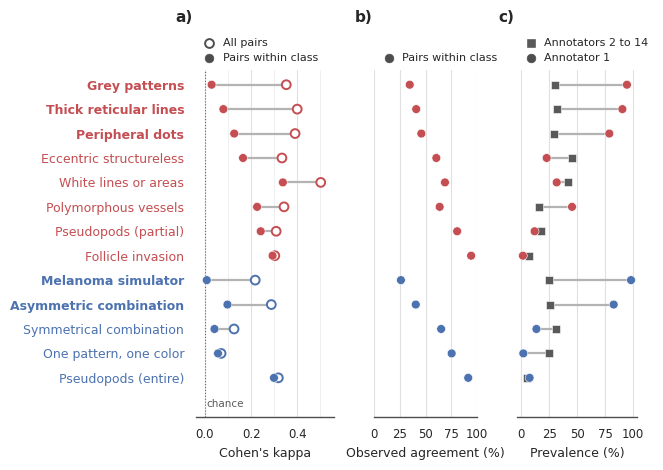

In [8]:
NAMES = {"TRBL": "Thick reticular lines", "ESA": "Eccentric structureless", "BDG": "Peripheral dots",
         "GP": "Grey patterns", "PV": "Polymorphous vessels", "PRL": "Pseudopods (partial)",
         "WLSA": "White lines or areas", "PIF": "Follicle invasion", "OPC": "One pattern, one color",
         "SPC": "Symmetrical combination", "PRLC": "Pseudopods (entire)", "APC": "Asymmetric combination",
         "MS": "Melanoma simulator"}
FLAGS = ["GP", "TRBL", "BDG", "ESA", "WLSA", "PV", "PRL", "PIF", "MS", "APC", "SPC", "OPC", "PRLC"]
shown = agree[(agree.prev_a1 > 5) | (agree.prev_others > 5)].index
check("Figure 1", "concepts above 5% for at least one rater group", sorted(shown), "13 concepts", sorted(shown) == sorted(FLAGS))

d = agree.loc[FLAGS, ["pool", "merged_prev", "kappa_all", "kappa_within", "observed_within", "prev_a1", "prev_others"]].reset_index()
d["observed_within"] = 100 * d["observed_within"]
d["top5"] = d.concept.isin(top5.index)
d.to_csv(os.path.join(OUT, "figure1_source_data.csv"), index=False)

sns.set_theme(style="whitegrid", context="paper", font="DejaVu Sans",
              rc={"font.size": 9, "axes.labelsize": 9, "xtick.labelsize": 8.5, "ytick.labelsize": 9,
                  "legend.fontsize": 8, "axes.edgecolor": "0.3", "grid.color": "0.88"})
pal = sns.color_palette("deep")
col = {"M": pal[3], "N": pal[0]}
d["y"] = np.arange(len(d))[::-1]
pc = [col[p] for p in d.pool]
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(6.6, 4.8), sharey=True, gridspec_kw={"width_ratios": [1.15, 0.85, 1.0]})
for r in d.itertuples():
    ax1.plot([r.kappa_within, r.kappa_all], [r.y, r.y], color="0.7", lw=1.6, zorder=1)
    ax3.plot([r.prev_others, r.prev_a1], [r.y, r.y], color="0.7", lw=1.6, zorder=1)
sns.scatterplot(x=d.kappa_all, y=d.y, ax=ax1, s=40, facecolor="white", edgecolor=pc, linewidth=1.4, zorder=2, label="All pairs")
sns.scatterplot(x=d.kappa_within, y=d.y, ax=ax1, s=40, color=pc, edgecolor="white", linewidth=0.4, zorder=3, label="Pairs within class")
sns.scatterplot(x=d.observed_within, y=d.y, ax=ax2, s=40, color=pc, edgecolor="white", linewidth=0.4, zorder=3, label="Pairs within class")
sns.scatterplot(x=d.prev_others, y=d.y, ax=ax3, s=38, marker="s", color="0.35", edgecolor="white", linewidth=0.4, zorder=2, label="Annotators 2 to 14")
sns.scatterplot(x=d.prev_a1, y=d.y, ax=ax3, s=40, color=pc, edgecolor="white", linewidth=0.4, zorder=3, label="Annotator 1")
ax1.set_yticks(d.y)
ax1.set_yticklabels([NAMES[f] for f in d.concept])
for t, p, b in zip(ax1.get_yticklabels(), d.pool, d.top5):
    t.set_color(col[p])
    t.set_fontweight("bold" if b else "normal")
ax1.axvline(0, color="0.4", lw=0.8, ls=":")
ax1.text(0.005, -1.05, "chance", fontsize=7.5, color="0.35", ha="left", va="center")
ax1.set_xlim(-0.04, 0.56)
ax1.set_xticks([0, 0.2, 0.4])
ax1.set_xticks([0.1, 0.3, 0.5], minor=True)
ax1.grid(axis="x", which="minor", color="0.93", lw=0.6)
ax1.tick_params(axis="x", which="minor", length=0)
ax1.set_xlabel("Cohen's kappa")
ax2.set_xlim(0, 100)
ax2.set_xticks([0, 25, 50, 75, 100])
ax2.set_xlabel("Observed agreement (%)")
ax3.set_xlim(-4, 104)
ax3.set_xticks([0, 25, 50, 75, 100])
ax3.set_xlabel("Prevalence (%)")
for ax in (ax1, ax2, ax3):
    ax.set_ylabel("")
    ax.set_ylim(-1.6, len(d) - 0.4)
    ax.grid(axis="y", visible=False)
    ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(-0.03, 1.0), ncol=1, handletextpad=0.2, borderaxespad=0.2)
    for h in ax.get_legend().legend_handles:
        h.set_edgecolor("0.3")
    sns.despine(ax=ax, left=True)
ax1.get_legend().legend_handles[0].set_facecolor("white")
ax1.get_legend().legend_handles[1].set_facecolor("0.3")
ax2.get_legend().legend_handles[0].set_facecolor("0.3")
ax3.get_legend().legend_handles[1].set_facecolor("0.3")
for ax, lab in [(ax1, "a)"), (ax2, "b)"), (ax3, "c)")]:
    ax.text(-0.02, 1.13, lab, transform=ax.transAxes, fontweight="bold", fontsize=11, ha="right", va="bottom")
fig.tight_layout(w_pad=0.8)
for ext in ("pdf", "png", "jpg"):
    fig.savefig(os.path.join(OUT, f"figure1.{ext}"), dpi=600 if ext != "pdf" else None, bbox_inches="tight")
plt.show()

## 5. Composite and contradictory concept labels

We verify the counts in the paragraph on the pattern-complexity concepts and on the None option. Each check targets one sentence of that paragraph.

In [9]:
pc_mel = ann.loc[ann.benign_malignant == 1, ["OPC", "SPC", "APC"]].to_numpy().sum()
check("Composite", "positive pattern-complexity concept labels in melanoma records", int(pc_mel), 0, pc_mel == 0)

within = int(((ann.OPC == 1) & (ann.APC == 1)).sum())
after = int(((gt.OPC == 1) & (gt.APC == 1)).sum())
check("Composite", "single pattern with asymmetric combination, records then merged images", (within, after), "(6, 297)", (within, after) == (6, 297))

none_only_mel = int(((ann.benign_malignant == 1) & (ann["None"] == 1) & (ann[M].sum(axis=1) == 0)).sum())
check("Composite", "melanoma records with only the None option", none_only_mel, 46, none_only_mel == 46)
mel_without = int((gt.loc[Y == 1, M].max(axis=1) == 0).sum())
check("Composite", "merged melanoma images without a melanoma concept", mel_without, 0, mel_without == 0)

Composite | positive pattern-complexity concept labels in melanoma records = 0 | manuscript 0
Composite | single pattern with asymmetric combination, records then merged images = (6, 297) | manuscript (6, 297)
Composite | melanoma records with only the None option = 46 | manuscript 46
Composite | merged melanoma images without a melanoma concept = 0 | manuscript 0


## 6. Clinicians without knowledge of the histopathological diagnosis

We use the phase 1 records, where clinicians selected concepts without knowing the histopathological diagnosis. We verify the counts and percentages in the paragraph on these clinicians.

In [10]:
S = (study[ALL] == 1).astype(int)
dx_mel = study.prediction == 1
s_m = S[M].max(axis=1) == 1
s_n = S[N].max(axis=1) == 1
check("Clinicians", "clinicians in phase 1", study.participant.nunique(), 113, study.participant.nunique() == 113)
check("Clinicians", "phase 1 records", len(study), 1560, len(study) == 1560)
cross = int((s_m & ~dx_mel).sum() + (s_n & dx_mel).sum())
check("Clinicians", "records with a concept outside the pool of the own diagnosis", cross, 0, cross == 0)
check("Clinicians", "records combining both pools", int((s_m & s_n).sum()), 0, (s_m & s_n).sum() == 0)

hist_nev = (study.benign_malignant == 0).to_numpy()
mel_in_nev = int((s_m & hist_nev).sum())
nev_in_mel = int((s_n & ~hist_nev).sum())
counts = (mel_in_nev, int(hist_nev.sum()), nev_in_mel, int((~hist_nev).sum()))
check("Clinicians", "melanoma concepts in nevus records and nevus concepts in melanoma records", counts, "(206, 781, 279, 779)",
      counts == (206, 781, 279, 779))
pct = (float(round(100 * mel_in_nev / hist_nev.sum(), 1)), float(round(100 * nev_in_mel / (~hist_nev).sum(), 1)))
check("Clinicians", "the same shares in percent", pct, "(26.4, 35.8)", pct == (26.4, 35.8))

Clinicians | clinicians in phase 1 = 113 | manuscript 113
Clinicians | phase 1 records = 1560 | manuscript 1560
Clinicians | records with a concept outside the pool of the own diagnosis = 0 | manuscript 0
Clinicians | records combining both pools = 0 | manuscript 0
Clinicians | melanoma concepts in nevus records and nevus concepts in melanoma records = (206, 781, 279, 779) | manuscript (206, 781, 279, 779)
Clinicians | the same shares in percent = (26.4, 35.8) | manuscript (26.4, 35.8)


## 7. Summary of all checks

The table lists every check of this notebook with the value we computed and the value in the manuscript. The notebook reaches this cell only when all assertions pass.

In [11]:
summary = pd.DataFrame(RESULTS)
print(f"{summary.passed.sum()} of {len(summary)} checks passed")
summary

41 of 41 checks passed


,sentence,check,value,manuscript,passed
0,Opening,images,3611,3611,True
1,Opening,lesions,1981,1981,True
2,Opening,pool concepts,18,18,True
3,Opening,annotating dermatologists,14,14,True
4,Opening,annotation files with regions of interest,6498,6498,True
5,Protocol,diagnosis types,[histo],histopathology only,True
6,Protocol,melanoma and nevus concepts,"(10, 8)","(10, 8)",True
7,Protocol,annotation records,6498,6498,True
8,Protocol,records with concepts from both pools,0,0,True
9,Protocol,images without a concept of their own pool,0,0,True
